# Etapa 4: rede neural

Entrada: `data/processed/emprestimos.csv` e os pontos de referência da etapa 3 (`resultados/referencias.csv`).

A rede é um MLP (*multilayer perceptron*) do scikit-learn: camadas ocultas com ativação ReLU, um neurônio de saída com sigmoide e otimizador Adam. O código fica em `src/rede.py`. A etapa responde a cinco perguntas:

1. Por que padronizar os atributos?
2. Quantos neurônios a rede precisa?
3. Como a rede aprende ao longo das épocas, e quando parar?
4. Com hiperparâmetros escolhidos por busca em grade, a rede supera os pontos de referência? Quanto tempo ela leva?
5. Onde a rede erra?

## 0. Configuração

In [1]:
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import GridSearchCV, cross_val_score, train_test_split
from sklearn.tree import DecisionTreeClassifier

from src import avaliacao, config, rede

# Algumas redes da busca em grade atingem o limite de épocas sem convergir; o aviso repetiria
# centenas de vezes. O número de épocas de cada rede final fica registrado nos resultados.
warnings.filterwarnings("ignore", category=ConvergenceWarning)

X, y = avaliacao.carregar()
referencias = pd.read_csv(config.RESULTS_DIR / "referencias.csv")
media_ref = referencias.groupby("modelo")["acurácia"].mean()
print(X.shape)

(4269, 11)


## 1. A primeira rede

Uma camada oculta com 16 neurônios, atributos padronizados e as opções padrão de `src/rede.py`: early stopping com 10% do treino como validação e paciência de 30 épocas. Divisão principal (seed 42).

In [2]:
X_tr, X_te, y_tr, y_te = avaliacao.dividir(X, y, config.RANDOM_STATE)
primeira = rede.rede(camadas=(16,), seed=0)
metricas, _ = avaliacao.treinar_e_medir(primeira, X_tr, y_tr, X_te, y_te)
pd.Series(metricas).to_frame("primeira rede")

,primeira rede
acurácia,0.922717
F1 macro,0.917435
AUC,0.975664
erros,66.000000
tempo de treino (s),0.174410
tempo da busca (s),NaN
tempo de previsão (ms),0.587300
épocas,90.000000


## 2. Por que padronizar

A rede multiplica cada atributo por um peso. Sem padronização, a renda (milhões) e o número de dependentes (0 a 5) entram em escalas que diferem por um fator de milhões, e os atributos em dinheiro dominam as somas. A padronização leva cada atributo a média 0 e desvio 1, calculados só com o treino. A mesma rede, com e sem padronização, nas 10 seeds:

In [3]:
def com_e_sem_padronizacao(seed):
    return {
        "rede sem padronização": rede.rede(camadas=(16,), seed=seed, padronizar=False),
        "rede com padronização": rede.rede(camadas=(16,), seed=seed),
    }

padronizacao = avaliacao.rodar_seeds(com_e_sem_padronizacao, X, y)
avaliacao.resumir(padronizacao)[["acurácia", "AUC", "erros (média)"]]

,acurácia,AUC,erros (média)
modelo,,,
rede sem padronização,59.5 ± 3.1,51.0 ± 2.1,345.7
rede com padronização,93.9 ± 0.7,98.1 ± 0.5,52.4


Sem padronização, a rede fica perto (ou abaixo) do piso de 62,2%, o acerto de responder sempre "aprovado": ela não aprende. Com padronização, passa da regra de um corte. Para as árvores isso não importa, porque uma pergunta como "renda ≤ 5 milhões?" funciona em qualquer escala; para a rede, é indispensável.

## 3. Quantos neurônios

Acurácia de validação cruzada (5 partes, dentro do treino da seed 42) com 1 a 64 neurônios por camada, em redes de uma e de duas camadas ocultas. Para medir só a capacidade da rede, todas usam taxa de aprendizado 0,01 e treinam até convergir, sem early stopping. As linhas cinza são as médias no teste da regra de um corte e da árvore de decisão (etapa 3).

,1 camada oculta,2 camadas ocultas
neurônios por camada,,
1,0.9344,0.9473
2,0.9616,0.9719
4,0.9719,0.9455
8,0.9634,0.9795
16,0.9640,0.9678
32,0.9611,0.9584
64,0.9540,0.9616


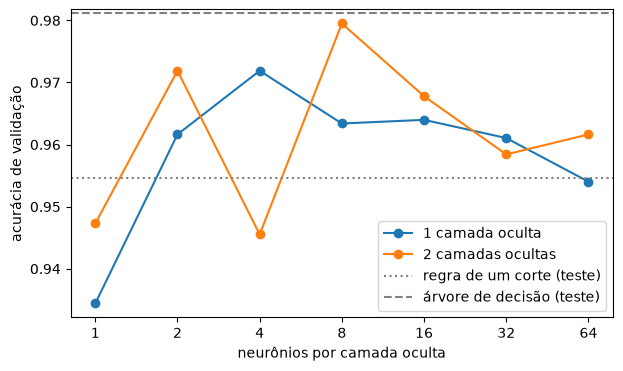

In [4]:
neuronios = [1, 2, 4, 8, 16, 32, 64]
cv = avaliacao.validacao_cruzada(config.RANDOM_STATE)
curvas = {}
for n_camadas in [1, 2]:
    nome = "1 camada oculta" if n_camadas == 1 else "2 camadas ocultas"
    curvas[nome] = [
        cross_val_score(rede.rede(camadas=(n,) * n_camadas, seed=0, learning_rate_init=0.01, early_stopping=False),
                        X_tr, y_tr, cv=cv, n_jobs=-1).mean()
        for n in neuronios
    ]
curva_neuronios = pd.DataFrame(curvas, index=pd.Index(neuronios, name="neurônios por camada"))
display(curva_neuronios.round(4))

fig, ax = plt.subplots(figsize=(7, 4))
for nome in curva_neuronios:
    ax.plot(curva_neuronios.index, curva_neuronios[nome], marker="o", label=nome)
ax.axhline(media_ref["regra de um corte"], color="gray", linestyle=":", label="regra de um corte (teste)")
ax.axhline(media_ref["árvore de decisão"], color="gray", linestyle="--", label="árvore de decisão (teste)")
ax.set_xscale("log", base=2)
ax.set_xticks(neuronios, neuronios)
ax.set_xlabel("neurônios por camada oculta")
ax.set_ylabel("acurácia de validação")
ax.legend()
plt.show()

## 4. A rede ao longo das épocas

Uma rede de 32 neurônios treinada época por época, 400 vezes, sem early stopping. O treino da seed 42 é dividido em 80% para treinar e 20% para validar. Duas taxas de aprendizado são comparadas, e as linhas verticais marcam onde o early stopping pararia com paciência de 10 épocas (o padrão do scikit-learn) e de 30 (a usada aqui).

In [5]:
X_sub, X_val, y_sub, y_val = train_test_split(X_tr, y_tr, test_size=0.2, stratify=y_tr, random_state=0)
curvas_epoca = {
    taxa: rede.curva_por_epoca(X_sub, y_sub, X_val, y_val, camadas=(32,), epocas=400, seed=0,
                               learning_rate_init=taxa)
    for taxa in [1e-3, 1e-2]
}

paradas = []
for taxa, curva in curvas_epoca.items():
    for paciencia in [10, 30]:
        epoca = rede.epoca_de_parada(curva["acurácia validação"], paciencia)
        paradas.append({"taxa de aprendizado": taxa, "paciência": paciencia, "época de parada": epoca,
                        "acurácia de validação na parada": round(curva.loc[epoca, "acurácia validação"], 4),
                        "melhor acurácia nas 400 épocas": round(curva["acurácia validação"].max(), 4)})
paradas = pd.DataFrame(paradas)
paradas

,taxa de aprendizado,paciência,época de parada,acurácia de validação na parada,melhor acurácia nas 400 épocas
0,0.001,10,37,0.9209,0.9649
1,0.001,30,217,0.9546,0.9649
2,0.010,10,54,0.9678,0.9736
3,0.010,30,94,0.9707,0.9736


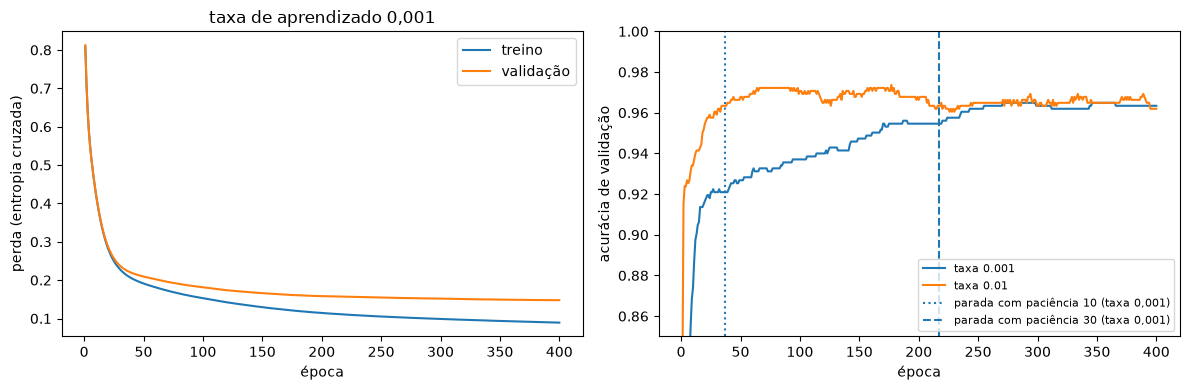

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
lenta = curvas_epoca[1e-3]
ax1.plot(lenta.index, lenta["perda treino"], label="treino")
ax1.plot(lenta.index, lenta["perda validação"], label="validação")
ax1.set_xlabel("época")
ax1.set_ylabel("perda (entropia cruzada)")
ax1.set_title("taxa de aprendizado 0,001")
ax1.legend()

for taxa, cor in [(1e-3, "tab:blue"), (1e-2, "tab:orange")]:
    curva = curvas_epoca[taxa]
    ax2.plot(curva.index, curva["acurácia validação"], color=cor, label=f"taxa {taxa:g}")
for _, linha in paradas[paradas["taxa de aprendizado"] == 1e-3].iterrows():
    ax2.axvline(linha["época de parada"], color="tab:blue", linestyle=":" if linha["paciência"] == 10 else "--",
                label=f"parada com paciência {int(linha['paciência'])} (taxa 0,001)")
ax2.set_xlabel("época")
ax2.set_ylabel("acurácia de validação")
ax2.set_ylim(0.85, 1.0)
ax2.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 5. Busca em grade e as 10 seeds

Em cada seed, uma busca em grade com validação cruzada de 5 partes dentro do treino escolhe a arquitetura (8, 16, 32 ou 64 neurônios numa camada; 32-16 ou 64-32 em duas), a regularização L2 (`alpha` = 0,0001 ou 0,01) e a taxa de aprendizado (0,001 ou 0,01): 24 combinações. Todas usam early stopping com paciência de 30 épocas. O protocolo de tempo é o mesmo da etapa 3: um núcleo, aquecimento descartado, busca medida à parte do treino final.

In [7]:
def redes(seed):
    return {"rede neural": GridSearchCV(rede.rede(seed=seed), rede.GRADE,
                                        cv=avaliacao.validacao_cruzada(seed), n_jobs=1)}

resultados_rede = avaliacao.rodar_seeds(redes, X, y)
resultados_rede.to_csv(config.RESULTS_DIR / "rede.csv", index=False)

todos = pd.concat([referencias, resultados_rede], ignore_index=True)
avaliacao.resumir(todos)

,acurácia,F1 macro,AUC,erros (média),tempo de treino (s) · mediana,tempo da busca (s) · mediana,tempo de previsão (ms) · mediana
modelo,,,,,,,
classe majoritária,62.2 ± 0.0,38.3 ± 0.0,50.0 ± 0.0,323.0,0.0002,NaN,0.0315
regra de um corte,95.5 ± 0.6,95.3 ± 0.6,96.2 ± 0.5,38.8,0.0019,NaN,0.3336
regressão logística,91.9 ± 1.1,91.3 ± 1.2,97.0 ± 0.5,69.5,0.0035,NaN,0.5340
árvore de decisão,98.1 ± 0.4,98.0 ± 0.5,98.7 ± 0.6,16.0,0.0037,0.6516,0.3286
random forest,98.3 ± 0.4,98.2 ± 0.5,99.8 ± 0.1,14.5,0.4898,NaN,15.2717
rede neural,96.4 ± 1.1,96.1 ± 1.2,99.3 ± 0.4,30.9,0.1833,23.5267,0.5821


Hiperparâmetros escolhidos e épocas de treino da rede final em cada seed:

In [8]:
display(resultados_rede["hiperparâmetros"].value_counts().to_frame("seeds"))
resultados_rede["épocas"].describe()[["min", "50%", "max"]].to_frame("épocas da rede final")

,seeds
hiperparâmetros,
"{'mlp__alpha': 0.0001, 'mlp__hidden_layer_sizes': (32, 16), 'mlp__learning_rate_init': 0.01}",4
"{'mlp__alpha': 0.01, 'mlp__hidden_layer_sizes': (32, 16), 'mlp__learning_rate_init': 0.01}",3
"{'mlp__alpha': 0.0001, 'mlp__hidden_layer_sizes': (8,), 'mlp__learning_rate_init': 0.01}",1
"{'mlp__alpha': 0.0001, 'mlp__hidden_layer_sizes': (64, 32), 'mlp__learning_rate_init': 0.01}",1
"{'mlp__alpha': 0.01, 'mlp__hidden_layer_sizes': (64, 32), 'mlp__learning_rate_init': 0.01}",1


,épocas da rede final
min,40.0
50%,66.5
max,121.0


## 6. Comparações seed a seed

In [9]:
pares = todos.pivot(index="seed", columns="modelo", values="acurácia")
pd.DataFrame({
    f"rede − {outro}": {
        "diferença média (pontos)": round(100 * (pares["rede neural"] - pares[outro]).mean(), 2),
        "desvio (pontos)": round(100 * (pares["rede neural"] - pares[outro]).std(), 2),
        "seeds com a rede melhor": int((pares["rede neural"] > pares[outro]).sum()),
    }
    for outro in ["regra de um corte", "regressão logística", "árvore de decisão", "random forest"]
}).T

,diferença média (pontos),desvio (pontos),seeds com a rede melhor
rede − regra de um corte,0.93,1.13,8.0
rede − regressão logística,4.52,1.29,10.0
rede − árvore de decisão,-1.74,0.94,0.0
rede − random forest,-1.92,1.19,1.0


## 7. Onde a rede erra

Na divisão principal (seed 42), a rede e a árvore de decisão, cada uma com sua busca em grade, são comparadas por faixa de score e na exceção dos prazos curtos (score abaixo de 550 e prazo de até 4 anos).

In [10]:
GRADE_ARVORE = {"criterion": ["gini", "entropy"], "max_depth": [3, 5, 8, 12, None], "min_samples_leaf": [1, 5, 20]}
cv = avaliacao.validacao_cruzada(config.RANDOM_STATE)
melhor_rede = GridSearchCV(rede.rede(seed=0), rede.GRADE, cv=cv, n_jobs=-1).fit(X_tr, y_tr)
melhor_arvore = GridSearchCV(DecisionTreeClassifier(random_state=0), GRADE_ARVORE, cv=cv, n_jobs=-1).fit(X_tr, y_tr)
modelos_seed42 = {"rede neural": melhor_rede, "árvore de decisão": melhor_arvore}

faixa = pd.cut(X_te["cibil_score"], [299, 499, 549, 599, 900], labels=["< 500", "500 a 549", "550 a 599", "≥ 600"])
excecao = (X_te["cibil_score"] < 550) & (X_te["loan_term"] <= 4)
tabela = pd.DataFrame({"pedidos de teste": faixa.value_counts().sort_index()})
resumo_excecao = {}
for nome, modelo in modelos_seed42.items():
    erro = pd.Series(modelo.predict(X_te) != y_te.to_numpy(), index=X_te.index)
    tabela[f"erros: {nome}"] = erro.groupby(faixa, observed=False).sum()
    resumo_excecao[nome] = {"erros na exceção": int((erro & excecao).sum()), "erros fora dela": int((erro & ~excecao).sum())}
display(tabela)
print("pedidos na exceção (score < 550 e prazo ≤ 4):", int(excecao.sum()))
pd.DataFrame(resumo_excecao).T

,pedidos de teste,erros: rede neural,erros: árvore de decisão
cibil_score,,,
< 500,275,6,8
500 a 549,70,6,4
550 a 599,73,9,1
≥ 600,436,2,2


pedidos na exceção (score < 550 e prazo ≤ 4): 52


,erros na exceção,erros fora dela
rede neural,8,15
árvore de decisão,12,3


Probabilidade de aprovação dada por cada modelo, em função do score, para os pedidos de teste. A cor é a situação real.

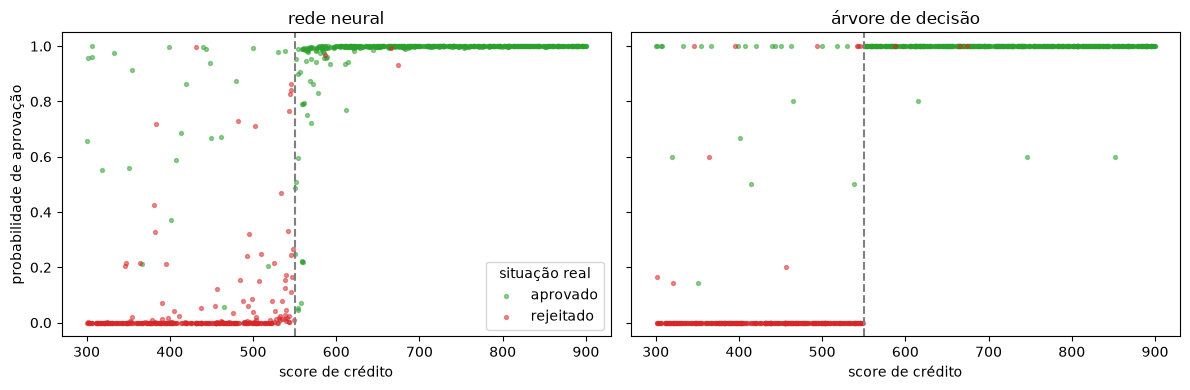

In [11]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (nome, modelo) in zip(eixos, modelos_seed42.items()):
    probabilidade = modelo.predict_proba(X_te)[:, 1]
    for classe, cor, rotulo in [(1, "tab:green", "aprovado"), (0, "tab:red", "rejeitado")]:
        marca = y_te.to_numpy() == classe
        ax.scatter(X_te["cibil_score"][marca], probabilidade[marca], s=8, alpha=0.5, color=cor, label=rotulo)
    ax.axvline(550, color="gray", linestyle="--")
    ax.set_title(nome)
    ax.set_xlabel("score de crédito")
eixos[0].set_ylabel("probabilidade de aprovação")
eixos[0].legend(title="situação real")
plt.tight_layout()
plt.show()

**Resultado.**

- **Padronização é indispensável.** Sem ela, a rede acerta 59,5 ± 3,1%, abaixo do piso de 62,2%, com AUC de 51 (o mesmo que sortear). Com ela, a mesma rede vai a 93,9 ± 0,7%.
- **Poucos neurônios bastam.** Com 1 neurônio por camada, a rede fica perto da regressão logística (93% a 95%). Com 2 a 8 neurônios, já passa de 97%, e o melhor ponto, duas camadas de 8, chega a 98,0% na validação. Mais neurônios não ajudam. A curva é irregular porque cada ponto é uma única rede, e a rede depende dos pesos iniciais sorteados.
- **A taxa de aprendizado e a paciência decidem quando a rede para.** Com taxa 0,001, a rede aprende devagar: o early stopping com a paciência padrão (10 épocas) pararia na época 37, com 92,1% de validação, enquanto a mesma rede chega a 96,5% se continuar. Com paciência 30, ela para na época 217. Com taxa 0,01, chega a 97% em menos de 100 épocas. A perda de validação se estabiliza enquanto a de treino continua caindo: a partir daí, a rede começa a decorar o treino. A busca em grade escolheu a taxa 0,01 nas 10 seeds, e duas camadas ocultas em 9 delas (32-16 em 6).
- **Contra os pontos de referência** (10 seeds): a rede acerta 96,4 ± 1,1%. Supera a regressão logística nas 10 seeds (+4,5 pontos) e a regra de um corte em 8 de 10 (+0,9 ponto, uma vantagem pequena perto do desvio). Perde para a árvore de decisão nas 10 seeds (−1,7 ponto) e para a Random Forest em 9 de 10 (−1,9 ponto). Também é menos estável: o desvio entre seeds (1,1 ponto) é quase três vezes o da árvore. A AUC da rede (99,3) é maior que a da árvore (98,7): ela ordena bem os pedidos, mas o corte em probabilidade 0,5 erra os que ficam perto do degrau.
- **Tempo** (um núcleo, mediana): treinar a rede final leva cerca de 0,2 s, umas 50 vezes a árvore e menos da metade da Random Forest. A busca em grade (24 combinações × 5 partes) leva cerca de 24 s por seed, contra menos de 1 s da árvore. Prever leva menos de 1 ms, como a árvore, enquanto a Random Forest leva cerca de 15 ms.
- **Onde a rede erra** (seed 42): 23 erros, contra 15 da árvore. Os erros da rede se concentram logo acima do degrau, com score entre 550 e 599 (9 erros, contra 1 da árvore): a rede desenha uma rampa onde a regra é um degrau, como mostra o último gráfico. Já a árvore erra sobretudo a exceção dos prazos curtos (12 dos seus 15 erros), onde a rede erra menos (8).

Nesta base, a rede neural funciona, mas não compensa: uma árvore treina dezenas de vezes mais rápido, acerta mais e tem regras legíveis. O motivo é a forma da regra que gerou os rótulos, um degrau no score de crédito, que uma árvore representa com uma pergunta e uma rede só aproxima com uma curva.